# 1. Business hypothesis and experiment overview

| Item | Value |
|---|---|
| Experiment ID | `1.2_logistic_regression` (traditional models track) |
| Owner | Nigel Yap |
| Model | L2-regularised logistic regression (baseline) |
| Scope | Development comparison with `1.1_lightgbm_ranker`: 200 selection requests and 3,000 evaluation requests from validation, each against the full eligible catalogue |

**Business objective addressed.** *Relevant recommendations*: Stage 1 must keep the articles a reader would click inside the shortlist that the reranker receives.

**Hypothesis.** A linear model is the simple baseline. If the same information gives a similar shortlist without interactions, the extra complexity of tree models would not be justified. If it is clearly worse, that shows how much non-linear effects and interactions add.

**Version note.** Two earlier runs gave Recall@100 = 0.0 (`20261104_val3000_seed42` and `20261104_agebands_val3000_seed42`). The cause was a preprocessing bug: `ohe_category_020` almost never occurs in train, so standardising it divided by about 0.0006 and inflated about 1,370 catalogue articles above everything else. This version leaves binary columns unscaled, clips scaled values to +/-5 and keeps the five age bands. These changes were made after seeing validation results, so they are development decisions.

**Design.** The inputs are the same 200 features used by 1.1 (the slate-dependent features remain removed). Training uses recorded slates only, unshown articles are never labelled, and catalogue features are rebuilt with `1.1_lightgbm_ranker/catalogue_v4.py`. The bounded search is selected by known-click Recall@100 on the same 200 validation requests as 1.1, then nDCG@100, then the earlier trial. Test is not loaded, so its labels stay unread.

# 2. Setup and run configuration

In [1]:
import os, sys, json, time, pickle, shutil, platform, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd, pyarrow.parquet as pq, matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parent / "1.1_lightgbm_ranker"))
import catalogue_v4 as cv
warnings.filterwarnings("ignore", category=FutureWarning)

EXPERIMENT_ID = "1.2_logistic_regression"; OWNER = "Nigel Yap"; SEED = REQUEST_SEED = 42
RUN_ID = os.environ.get("BT4222_RUN_ID", "20261104_fixedscale_val3000_seed42")
DEV_FRAC = float(os.environ.get("BT4222_DEV_FRAC", "0"))
SELECTION_N = int(os.environ.get("BT4222_SEL_N", "200")); EVAL_N = int(os.environ.get("BT4222_EVAL_N", "3000"))
ROUNDS = int(os.environ.get("BT4222_ROUNDS", "400")); THREADS = int(os.environ.get("BT4222_THREADS", "14"))
SELECTION_K, EXPORT_K = 100, 200
SHARED = Path(os.environ.get("BT4222_SHARED", r"C:\Users\nigel\BT4222 Shared Final Folder"))
FEATURE_ROOT = SHARED / "feature_engineering_nov4"; SMALL = Path(r"C:\Users\nigel\bt4222-data\ebnerd_small")
TEST_ARTICLES = Path(r"C:\Users\nigel\OneDrive\Desktop\BT4222 Final\ebnerd_large\articles.parquet")
LGBM_RUN = Path.cwd().parent / "1.1_lightgbm_ranker" / "outputs" / "20261104_v4_union_fullval_seed42"
OUT = Path("outputs") / RUN_ID; PERSIST = Path(os.environ.get("BT4222_PERSIST_DIR", str(SHARED / "Experiments" / EXPERIMENT_ID / RUN_ID)))
for d in ["predictions/validation", "rankings/validation", "diagnostics/recorded_slates", "model", "tuning"]: (OUT / d).mkdir(parents=True, exist_ok=True)
def log(m):
    line = time.strftime("%H:%M:%S ") + m; print(line, flush=True)
    with open(OUT / "progress.log", "a", encoding="utf-8") as f: f.write(line + "\n")
log(f"start {RUN_ID} | selection {SELECTION_N} | evaluation {EVAL_N}")

11:59:45 start 20261104_fixedscale_val3000_seed42 | selection 200 | evaluation 3000


**Protocol.** Selection and evaluation requests are prefixes of the shared blake2b hash order, so they are identical to the requests used by 1.1. Validation is used for selection, so every score here is a **development result**. The 3,000 evaluation requests include the 200 selection requests.

# 3. Load and check shared data

In [2]:
state = json.load(open(FEATURE_ROOT / "feature_vocabulary.json", encoding="utf-8"))
FEATURES = json.load(open(LGBM_RUN / "model" / "model_config.json", encoding="utf-8"))["feature_names"]
assert not set(FEATURES) & set(cv.POOL_DEPENDENT) and len(FEATURES) == 200
data = {}
keys = ["user_id", "impression_id", "candidate_article_id", "impression_time"]
for sp in ["train", "validation"]:
    df = pd.read_parquet(FEATURE_ROOT / f"{sp}_features.parquet", columns=list(dict.fromkeys(keys + FEATURES + ["clicked"])))
    assert not df.duplicated(keys[:3]).any()
    df["behaviour_id"] = df.user_id.astype("int64").astype(str) + ":" + df.impression_id.astype("int64").astype(str)
    if DEV_FRAC > 0 and sp == "train":
        ids = df.behaviour_id.unique(); keep = set(np.random.default_rng(SEED).choice(ids, int(len(ids) * DEV_FRAC), replace=False)); df = df[df.behaviour_id.isin(keep)]
    df["g"] = pd.factorize(df.behaviour_id)[0]; data[sp] = df.sort_values("g", kind="stable").reset_index(drop=True)
    print(f"{sp}: rows {len(df):,} | requests {df.g.nunique():,} | click rate {df.clicked.mean():.4f}")
cat = cv.Catalogue([SMALL / "articles.parquet", TEST_ARTICLES], state)
assert cat.fingerprint == "cb89570c1bc70654", "catalogue differs from 1.1"
first = data["validation"].drop_duplicates("behaviour_id").set_index("behaviour_id")
reqs = cv.hash_order(first.reset_index()[["user_id", "impression_id"]], "validation", REQUEST_SEED)
known = data["validation"][data["validation"].clicked == 1].groupby("behaviour_id").candidate_article_id.apply(lambda s: set(s.astype("int64")))
reqs["known"] = reqs.behaviour_id.map(known).map(lambda s: s if isinstance(s, set) else set())
SEL, EVAL = reqs.head(SELECTION_N), reqs.head(EVAL_N)
ref = pd.read_parquet(LGBM_RUN / "predictions/validation/request_manifest.parquet", columns=["behaviour_id"]).head(EVAL_N)
assert ref.behaviour_id.tolist() == EVAL.behaviour_id.tolist(), "requests differ from 1.1"
PROFILES = cv.build_profiles(SMALL / "validation" / "history.parquet", EVAL.user_id.unique(), cat, state)
print(f"catalogue {cat.n:,} articles | selection {len(SEL)} | evaluation {len(EVAL)} | request order identical to 1.1")
def features_for(b, ix):
    r = first.loc[b]; sub = r.is_subscriber
    c = {"impression_time": r.impression_time.to_datetime64(), "is_sso_user": float(r.is_sso_user) if pd.notna(r.is_sso_user) else np.nan, "is_subscriber": bool(sub) if pd.notna(sub) else float("nan"),
         "is_front_page": float(r.is_front_page), "hour": float(r.hour), "day_of_week": float(r.day_of_week)}
    c.update({k: float(r[k]) for k in r.index if k.startswith("ohe_device_type_")})
    return cv.request_features(cat, PROFILES[int(r.user_id)], c, ix, FEATURES)
bad = 0; rows = 0
for b in SEL.behaviour_id.head(50):
    rec = data["validation"][data["validation"].behaviour_id == b]; ix = cat.pos.reindex(rec.candidate_article_id.to_numpy()).to_numpy().astype(int)
    bad += len(cv.compare_to_shared(rec[FEATURES], features_for(b, ix), FEATURES)); rows += len(rec)
print(f"feature rebuild check on {rows} shared rows: {bad} mismatched columns"); assert bad == 0

train: rows 2,585,747 | requests 232,887 | click rate 0.0904


validation: rows 344,666 | requests 29,110 | click rate 0.0849


catalogue 125,541 articles | selection 200 | evaluation 3000 | request order identical to 1.1


feature rebuild check on 437 shared rows: 0 mismatched columns


# 4. Prepare model inputs

In [3]:
# Fitted on train only. Skewed non-negative features are log-transformed, missing values use the train median, then every feature is standardised.
AGE_BANDS = ["age_le_6h", "age_6_24h", "age_24_72h", "age_72_168h", "age_gt_168h"]; NAMES = FEATURES + AGE_BANDS; ai = FEATURES.index("article_age_h")
LOG = ["body_word_count", "history_size", "median_history_body_word_count", "median_history_read_time", "history_clicks_7d", "same_category_mean_read_time"]
lx = [FEATURES.index(c) for c in LOG]
def base(X):
    X = np.array(X, dtype="float32"); a = X[:, ai].copy(); X[:, lx] = np.log1p(np.maximum(X[:, lx], 0)); X[:, ai] = 0
    B = np.stack([a <= 6, (a > 6) & (a <= 24), (a > 24) & (a <= 72), (a > 72) & (a <= 168), a > 168], axis=1).astype("float32"); return np.hstack([X, B])
Xb = base(data["train"][FEATURES].to_numpy("float32"))
MED = np.nanmedian(Xb, axis=0); MED = np.where(np.isnan(MED), 0, MED); miss = np.isnan(Xb); Xb[miss] = np.take(MED, np.where(miss)[1]); del miss
MU = Xb.mean(axis=0); SD = Xb.std(axis=0); SD = np.where(SD < 1e-8, 1.0, SD)
BIN = ((Xb == 0) | (Xb == 1)).all(axis=0); MU[BIN] = 0.0; SD[BIN] = 1.0; CLIP = 5.0          # binary columns stay 0/1; other columns are clipped
print("binary columns left unscaled:", int(BIN.sum()), "of", len(BIN))
Xtr = np.clip((Xb - MU) / SD, -CLIP, CLIP).astype("float32"); del Xb
def transform(X):
    X = base(X); m = np.isnan(X); X[m] = np.take(MED, np.where(m)[1]); return np.clip((X - MU) / SD, -CLIP, CLIP).astype("float32")
PREPROCESSING = dict(features=FEATURES, extra_columns=AGE_BANDS, age_band_edges_hours=[6, 24, 72, 168], age_column_replaced="article_age_h", log1p_features=LOG, median=MED, mean=MU, std=SD, clip=CLIP, binary_columns_unscaled=int(BIN.sum()), fitted_on="train only")
ytr = data["train"].clicked.to_numpy(); print(Xtr.shape)

binary columns left unscaled: 77 of 205


(2585747, 205)


In [4]:
def evaluate(specs, requests):
    out = {k: [] for k in specs}; ties = dict.fromkeys(specs, 0)
    for n, r in enumerate(requests.itertuples(), 1):
        ix = cat.eligible(first.loc[r.behaviour_id].impression_time.to_datetime64()); ids = cat.ids[ix]; M_ = features_for(r.behaviour_id, ix)
        for k, fn in specs.items():
            sc = fn(M_); order, cross = cv.top_k(sc, ids, EXPORT_K); ties[k] += int(cross); out[k].append(cv.retrieval_metrics(ids[order], r.known, (100, 200)))
        if n % 50 == 0: log(f"selection: {n}/{len(requests)} requests")
    return {k: {**pd.DataFrame(v).mean().to_dict(), "ties_at_cutoff": ties[k], "requests": len(v)} for k, v in out.items()}

# 5. Define and train model

In [5]:
from sklearn.linear_model import LogisticRegression
TRIALS = {"C0.01": 0.01, "C0.1": 0.1, "C1": 1.0}; models = {}
for n, c in TRIALS.items():
    t0 = time.time(); m = LogisticRegression(C=c, solver="lbfgs", max_iter=300, tol=1e-4, random_state=SEED).fit(Xtr, ytr); models[n] = m; log(f"{n}: fitted in {time.time()-t0:.0f}s, iterations {int(m.n_iter_[0])}")
    assert m.n_iter_[0] < 300, "logistic regression did not converge"
specs = {(n, 0): (lambda M_, m=m: transform(M_) @ m.coef_[0] + m.intercept_[0]) for n, m in models.items()}
RES = evaluate(specs, SEL)
trials = pd.DataFrame([dict(trial=n, checkpoint=k, **v) for (n, k), v in RES.items()]); trials.to_csv(OUT / "tuning" / "trials.csv", index=False)
win = trials.assign(_o=trials.trial.map({n: i for i, n in enumerate(TRIALS)})).sort_values(["recall@100", "ndcg@100", "_o"], ascending=[False, False, True]).iloc[0]
CHOSEN = win.trial; model = models[CHOSEN]; score = lambda M_: transform(M_) @ model.coef_[0] + model.intercept_[0]
pickle.dump(model, open(OUT / "model" / "model.pkl", "wb")); MODEL_DESC = dict(library="scikit-learn", C=TRIALS[CHOSEN], file="model.pkl")
log(f"SELECTED {CHOSEN} Recall@100={win['recall@100']:.4f} nDCG@100={win['ndcg@100']:.4f}")
trials.round(4)

12:01:10 C0.01: fitted in 31s, iterations 73


12:01:37 C0.1: fitted in 27s, iterations 73


12:02:02 C1: fitted in 25s, iterations 75


12:02:51 selection: 50/200 requests


12:03:42 selection: 100/200 requests


12:04:25 selection: 150/200 requests


12:05:06 selection: 200/200 requests


12:05:06 SELECTED C0.01 Recall@100=0.7300 nDCG@100=0.1712


,trial,checkpoint,recall@100,ndcg@100,recall@200,ndcg@200,ties_at_cutoff,requests
0,C0.01,0,0.730,0.1712,0.900,0.1952,30,200
1,C0.1,0,0.725,0.1672,0.905,0.1926,27,200
2,C1,0,0.720,0.1670,0.895,0.1917,28,200


# 6. Validation results

In [6]:
def auc_nd(g, y, s, k=5):
    d = pd.DataFrame({"g": g, "y": y.astype(float), "s": s}); d["r"] = d.groupby("g", sort=False)["s"].rank(method="average")
    a = d.assign(ry=d.r * d.y).groupby("g", sort=False).agg(n=("y", "size"), p=("y", "sum"), ry=("ry", "sum")); q = a.n - a.p; ok = (a.p > 0) & (q > 0)
    auc = ((a.ry - a.p * (a.p + 1) / 2) / (a.p * q))[ok].mean()
    d["ty"] = d.groupby(["g", "s"], sort=False)["y"].transform("mean"); d = d.sort_values(["g", "s"], ascending=[True, False], kind="stable"); d["pos"] = d.groupby("g", sort=False).cumcount() + 1
    dcg = (d.ty / np.log2(d.pos + 1)).where(d.pos <= k, 0).groupby(d.g, sort=False).sum(); disc = np.r_[0, np.cumsum(1 / np.log2(np.arange(1, k + 1) + 1))]; ideal = pd.Series(disc[np.minimum(a.p.to_numpy(), k).astype(int)], index=a.index)
    return float(auc), float((dcg / ideal).mean())
v = data["validation"]; sv = score(v[FEATURES].to_numpy("float32")); AUC, ND5 = auc_nd(v.g.to_numpy(), v.clicked.to_numpy(), sv); print(f"recorded-slate diagnostic (all validation rows): AUC {AUC:.4f}, nDCG@5 {ND5:.4f}")

recorded-slate diagnostic (all validation rows): AUC 0.6899, nDCG@5 0.5171


{'age_le_6h': 0.33399999141693115, 'age_6_24h': 0.44999998807907104, 'age_24_72h': -0.19300000369548798, 'age_72_168h': -0.4779999852180481, 'age_gt_168h': -0.875}


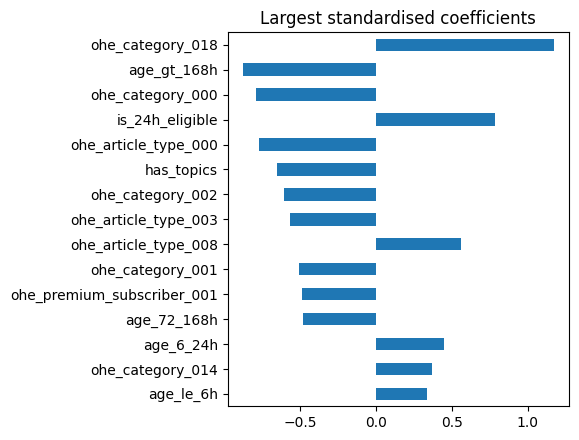

ohe_category_018              1.170
age_gt_168h                  -0.875
ohe_category_000             -0.792
is_24h_eligible               0.787
ohe_article_type_000         -0.772
has_topics                   -0.649
ohe_category_002             -0.603
ohe_article_type_003         -0.564
ohe_article_type_008          0.560
ohe_category_001             -0.508
ohe_premium_subscriber_001   -0.486
age_72_168h                  -0.478
age_6_24h                     0.450
ohe_category_014              0.367
age_le_6h                     0.334
dtype: float32

In [7]:
coef = pd.Series(model.coef_[0], index=NAMES); print(coef[AGE_BANDS].round(3).to_dict()); top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15); top.to_csv(OUT / "tuning" / "standardised_coefficients.csv", header=["coefficient"])
top.iloc[::-1].plot.barh(figsize=(6, 4.5), title="Largest standardised coefficients"); plt.tight_layout(); plt.show(); top.round(3)

**Reading the evidence (development results).**

- **Selected setting.** `C = 0.01`: Recall@100 = 0.730, nDCG@100 = 0.171 on the 200 selection requests. The three settings gave 0.730, 0.725 and 0.720, so they are hard to tell apart.
- **Baseline result.** On the 3,000 evaluation requests, Recall@100 = 0.673, nDCG@100 = 0.160, Recall@200 = 0.886. Recorded-slate AUC on all validation rows is 0.690.
- **Compared with the tree models on the 2,800 requests not used for selection.** XGBoost is ahead by 0.130 Recall@100 (95% CI 0.114 to 0.146) and LightGBM by 0.102 (0.086 to 0.118). At Recall@200 the gap is much smaller: XGBoost is ahead by 0.016 (0.009 to 0.024), and the difference from LightGBM is not distinguishable from zero (-0.005, CI -0.014 to +0.004). The tree models mainly place clicked articles higher.
- **Why two earlier runs scored 0.0.** `ohe_category_020` almost never occurs in train, so standardising it divided by about 0.0006 and inflated about 1,370 catalogue articles above everything else. Recorded-slate AUC did not reveal this, because those articles are rarely in the shown slates. The fix was to leave binary columns unscaled and clip other columns. This is a useful warning: a model can look healthy on shown slates and still fail on the catalogue.
- **Limits.** Coefficients are associations, not causes. The age bands and scaling fix were chosen after seeing validation results.

# 7. Predict and export

In [8]:
t0 = time.time(); bids, ia, sa, man = [], [], [], []
for i, r in enumerate(EVAL.itertuples(), 1):
    ix = cat.eligible(first.loc[r.behaviour_id].impression_time.to_datetime64()); ids = cat.ids[ix]; sc = score(features_for(r.behaviour_id, ix)); order, cross = cv.top_k(sc, ids, EXPORT_K); top = ids[order].astype("int64")
    bids.append(r.behaviour_id); ia.append(top); sa.append(np.asarray(sc[order], "float64")); man.append(dict(behaviour_id=r.behaviour_id, eligible_pool=len(ix), shortlist_len=len(top), known_clicks=len(r.known), known_clicks_eligible=len(r.known & set(ids)), tie_at_cutoff=bool(cross), **cv.retrieval_metrics(top, r.known, (100, 200))))
    if i % 500 == 0: log(f"export: {i}/{len(EVAL)} requests")
sig = lambda x: 1 / (1 + np.exp(-x)); lens = [len(x) for x in ia]
S = pd.DataFrame({"behaviour_id": np.repeat(np.array(bids, dtype=object), lens), "article_id": np.concatenate(ia), "rank": np.concatenate([np.arange(1, n + 1) for n in lens]), "score": np.concatenate(sa)}); S["click_probability"] = sig(S.score.to_numpy())
S.to_parquet(OUT / "predictions/validation/submission_article_scores.parquet", index=False, compression="zstd")
pd.DataFrame({"behaviour_id": bids, "article_ids": [x.tolist() for x in ia]}).to_parquet(OUT / "rankings/validation/submission_top_200.parquet", index=False, compression="zstd")
man = pd.DataFrame(man); man.to_parquet(OUT / "predictions/validation/request_manifest.parquet", index=False)
pd.DataFrame({"behaviour_id": v.behaviour_id, "article_id": v.candidate_article_id.astype("int64"), "score": sv, "click_probability": sig(sv)}).sort_values(["behaviour_id", "article_id"]).to_parquet(OUT / "diagnostics/recorded_slates/validation_scores.parquet", index=False, compression="zstd")
R2 = pd.read_parquet(OUT / "rankings/validation/submission_top_200.parquet"); S2 = pd.read_parquet(OUT / "predictions/validation/submission_article_scores.parquet")
assert len(R2) == len(EVAL) and R2.behaviour_id.is_unique and (R2.article_ids.map(len) == 200).all() and np.array_equal(np.concatenate(R2.article_ids.map(lambda x: np.asarray(x, "int64")).to_list()), S2.article_id.to_numpy()) and np.isfinite(S2.score).all()
metrics = {c: float(man[c].mean()) for c in ("recall@100", "ndcg@100", "recall@200", "ndcg@200")}; log(f"evaluation metrics {metrics} ({time.time()-t0:.0f}s)")
L1 = pd.read_parquet(LGBM_RUN / "predictions/validation/request_manifest.parquet"); lstm = pd.read_parquet(SHARED / "catalogue" / "lstm_per_request.parquet")
J = man.merge(L1, on="behaviour_id", suffixes=("", "_lgbm")).merge(lstm, on="behaviour_id"); rows = []
for k, q in (("recall@100", "known_click_recall@100"), ("ndcg@100", "observed_click_ndcg@100"), ("recall@200", "known_click_recall@200"), ("ndcg@200", "observed_click_ndcg@200")):
    for name, col in (("LightGBM", k + "_lgbm"), ("LSTM", q)):
        d = (J[k] - J[col]).to_numpy("float64"); se = d.std(ddof=1) / np.sqrt(len(J)); rows.append(dict(metric=k, compared_with=name, this_model=J[k].mean(), other=J[col].mean(), difference=d.mean(), ci_low=d.mean() - 1.96 * se, ci_high=d.mean() + 1.96 * se))
cmp_ = pd.DataFrame(rows); cmp_.to_csv(OUT / "tuning" / "paired_comparison_3000.csv", index=False); cmp_.round(4)

12:08:26 export: 500/3000 requests


12:12:08 export: 1000/3000 requests


12:14:58 export: 1500/3000 requests


12:18:37 export: 2000/3000 requests


12:22:05 export: 2500/3000 requests


12:25:42 export: 3000/3000 requests


12:25:43 evaluation metrics {'recall@100': 0.6734388888888889, 'ndcg@100': 0.16042746162930746, 'recall@200': 0.8856, 'ndcg@200': 0.19052023428639075} (1236s)


,metric,compared_with,this_model,other,difference,ci_low,ci_high
0,recall@100,LightGBM,0.6734,0.7732,-0.0998,-0.1150,-0.0845
1,recall@100,LSTM,0.6734,0.7161,-0.0426,-0.0609,-0.0244
2,ndcg@100,LightGBM,0.1604,0.2058,-0.0454,-0.0507,-0.0400
3,ndcg@100,LSTM,0.1604,0.1943,-0.0339,-0.0409,-0.0268
4,recall@200,LightGBM,0.8856,0.8906,-0.0050,-0.0135,0.0035
5,recall@200,LSTM,0.8856,0.8523,0.0333,0.0212,0.0454
6,ndcg@200,LightGBM,0.1905,0.2225,-0.0319,-0.0368,-0.0270
7,ndcg@200,LSTM,0.1905,0.2135,-0.0230,-0.0294,-0.0165


In [9]:
PR = OUT / "model" / "preprocessing.pkl"; pickle.dump(PREPROCESSING, open(PR, "wb"))
shutil.copy(Path.cwd().parent / "1.1_lightgbm_ranker" / "catalogue_v4.py", OUT / "model" / "catalogue_v4.py")
git = lambda *x: subprocess.run(["git", *x], capture_output=True, text=True).stdout.strip()
pk = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__)
if "lr" == "lr":
    import sklearn; pk["scikit-learn"] = sklearn.__version__
else: pk["xgboost"] = xgb.__version__
cfg = dict(experiment_id=EXPERIMENT_ID, run_id=RUN_ID, owner=OWNER, seed=SEED, request_sampling_seed=REQUEST_SEED, export_schema_version=4, prediction_pool="time_eligible_catalogue", selection_k=SELECTION_K, export_k=EXPORT_K,
    scope=dict(selection_requests=len(SEL), evaluation_requests=len(EVAL), split="validation", sampled_run=True, train_and_test_exported=False, training="all recorded train rows" if DEV_FRAC == 0 else f"DEV {DEV_FRAC}"),
    eligibility=dict(policy=cv.POLICY, catalogue_articles=cat.n, catalogue_fingerprint=cat.fingerprint, shared_catalogue_id_fingerprint_sha256="46bc36568a9bc1c6fdcfd101079b2cfef6f4192f4505032766fc858490c5f877"),
    selection=dict(primary="mean known-click Recall@100", secondary="mean observed-click nDCG@100", tie_rule="then earlier trial/checkpoint", selected=str(CHOSEN), trials=list(TRIALS)), model=MODEL_DESC,
    score_semantics=dict(score_type="logit", click_probability="sigmoid(score), uncalibrated"), features=FEATURES, packages=pk, code_commit=git("rev-parse", "HEAD"), uncommitted_changes=bool(git("status", "--porcelain")), persistent_artifact_location=str(PERSIST))
(OUT / "run_config.json").write_text(json.dumps(cfg, indent=2, default=str))
(OUT / "metrics.json").write_text(json.dumps(dict(note="development results; 3,000 validation requests include the 200 selection requests", evaluation=metrics, recorded_slate_diagnostic=dict(auc=AUC, ndcg5=ND5), selected_selection=dict(recall100=float(win["recall@100"]), ndcg100=float(win["ndcg@100"]))), indent=2))
(OUT / "requirements.txt").write_text("\n".join(f"{k}=={v}" for k, v in pk.items() if k != "python") + "\npyarrow\nscipy\nmatplotlib\n")

72

# 8. Reload check

In [10]:
shutil.copytree(OUT, PERSIST, dirs_exist_ok=True)
if "lr" == "lr":
    rm = pickle.load(open(PERSIST / "model" / "model.pkl", "rb")); pr = pickle.load(open(PERSIST / "model" / "preprocessing.pkl", "rb"))
    def re_score(M_):
        X = base(M_); m = np.isnan(X); X[m] = np.take(pr["median"], np.where(m)[1]); return np.clip((X - pr["mean"]) / pr["std"], -pr["clip"], pr["clip"]).astype("float32") @ rm.coef_[0] + rm.intercept_[0]
else:
    rb = xgb.Booster(); rb.load_model(str(PERSIST / "model" / "model.json")); re_score = lambda M_: rb.inplace_predict(M_, predict_type="margin", missing=np.nan)
ex = pd.read_parquet(PERSIST / "predictions/validation/submission_article_scores.parquet"); worst = 0.0
for b in EVAL.behaviour_id.head(5):
    ix = cat.eligible(first.loc[b].impression_time.to_datetime64()); r_ = ex[ex.behaviour_id == b].set_index("article_id").score
    worst = max(worst, float(np.abs(pd.Series(re_score(features_for(b, ix)), index=cat.ids[ix]).reindex(r_.index).to_numpy() - r_.to_numpy()).max()))
print(f"max abs difference {worst:.2e}"); assert worst < 1e-5; log("RELOAD CHECK PASSED")

max abs difference 0.00e+00
12:25:45 RELOAD CHECK PASSED


# 9. Business interpretation and handoff

**Finding.** Logistic regression is a working baseline at Recall@100 = 0.673 (3,000 validation requests, development result). It is clearly behind both tree models at Recall@100 and nDCG, so non-linear effects and interactions add real value for shortlisting. It remains close to the trees at Recall@200.

**Relation to the business objective.** Stage 1 must keep clicked articles available to the reranker. The baseline shows how much of that task a simple linear model can do, and why a more flexible model is justified.

**Limitations.** This is a sampled run. It covers 3,000 validation requests, and train and test catalogue exports were not run. It is a baseline, not a model selected for Stage 2.

**Handoff.** Bundle: `Experiments/1.2_logistic_regression/outputs/20261104_fixedscale_val3000_seed42/`, with an identical copy in the shared folder. Earlier zero-recall runs are kept locally only as a record of the bug and should not be used. The final track model is `1.3_xgboost`.